# Diferencia de tasa de empleo entre nacidos en el extranjero y nacidos en el país

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "brecha-empleo-nacidos-extranjero"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Diferencia de tasa de empleo entre nacidos en el extranjero y nacidos en el país"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Puntos porcentuales"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La tasa de empleo de las personas de 20 a 64 años nacidas en el extranjero menos la de las nacidas en el país, en puntos porcentuales.

**Cómo se lee.** Un valor de −5 significa que la tasa de empleo de los nacidos en el extranjero es cinco puntos más baja que la de los nacidos en el país; un valor positivo, que es más alta. La diferencia puede cambiar porque sube o baja cualquiera de las dos tasas: el notebook muestra las dos por separado.

**Limitaciones.**
- Se usa el país de nacimiento, no la nacionalidad: incluye a las personas nacidas fuera que tienen la nacionalidad del país.
- La población nacida en el extranjero tiene otra estructura de edades, de estudios y de años de residencia, que la tasa no descuenta.
- EE. UU. y Canadá proceden de la OCDE, con el tramo de 15 a 64 años; España y la UE-27, de Eurostat, de 20 a 64.

## 2. Descarga

- **España y UE-27:** Eurostat `lfsa_ergacob`: tasa de empleo (`PC`) de 20 a 64 años, ambos sexos, nacidos en el extranjero (`c_birth=FOR`) y en el país (`NAT`).
- **EE. UU. y Canadá:** OCDE, resultados laborales de los inmigrantes (`OECD.ELS.IMD,DSD_MIG@DF_MIG_NUP_SEX`, versión 1.0): tasa de empleo (`EMP_WAP`) de 15 a 64 años, ambos sexos, nacidos en el extranjero (`FB`) y en el país (`NB`).
- **OCDE:** sin dato; la fuente no publica el agregado.
- **Solo para las notas:** la misma diferencia de España con la OCDE, para compararla con la de Eurostat.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

HOY = date.today().isoformat()
FILTROS_EU = {"age": "Y20-64", "sex": "T", "unit": "PC"}
eu = {c: eurostat.get("lfsa_ergacob", {**FILTROS_EU, "c_birth": c}, desde=DESDE) for c in ("FOR", "NAT")}

AREAS_OCDE = {"USA": "eeuu", "CAN": "canada", "ESP": "espana", "OECD": "ocde"}
DATAFLOW_MIG = "OECD.ELS.IMD,DSD_MIG@DF_MIG_NUP_SEX,1.0"
# Dimensiones: país . nacionalidad . frecuencia . medida . sexo . lugar de nacimiento . estudios . unidad
CLAVE_MIG = "{AREA}._Z.A.EMP_WAP._T.{NAC}._Z.PT_WAP_SUB"
oc = {n: oecd.get(DATAFLOW_MIG, CLAVE_MIG.replace("{NAC}", n), areas=AREAS_OCDE, desde=DESDE) for n in ("FB", "NB")}
for nombre, (d, _) in [*eu.items(), *oc.items()]:
    print(nombre, d.groupby("serie")["periodo"].agg(["min", "max"]).to_dict("index"))

FOR {'espana': {'min': 1995, 'max': 2025}, 'ue27': {'min': 2002, 'max': 2025}}
NAT {'espana': {'min': 1995, 'max': 2025}, 'ue27': {'min': 2002, 'max': 2025}}
FB {'canada': {'min': 2008, 'max': 2024}, 'eeuu': {'min': 2000, 'max': 2024}, 'espana': {'min': 2000, 'max': 2024}}
NB {'canada': {'min': 2008, 'max': 2024}, 'eeuu': {'min': 2000, 'max': 2024}, 'espana': {'min': 2000, 'max': 2024}}


## 3. Transformación

1. **Diferencia:** tasa de los nacidos en el extranjero menos la de los nacidos en el país, en cada año en que la fuente publica las dos.
2. España y UE-27 con Eurostat (20 a 64 años); EE. UU. y Canadá con la OCDE (15 a 64 años). La OCDE no publica el agregado de sus miembros y la serie `ocde` queda sin dato; tampoco se usa su serie `EU27_2020`, que solo tiene algunos años.
3. **Comparación de España** con la OCDE (15 a 64 años), para las notas.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


def brecha(extranjero, nativo):
    """Diferencia, en puntos, entre dos DataFrames estándar (mismas series y años)."""
    a = extranjero.set_index(["serie", "periodo"])["valor"]
    b = nativo.set_index(["serie", "periodo"])["valor"]
    d = (a - b).dropna()
    return d.rename("valor").reset_index()


b_eu = brecha(eu["FOR"][0], eu["NAT"][0])
b_oc = brecha(oc["FB"][0], oc["NB"][0])
df = pd.concat([b_eu, b_oc[b_oc["serie"].isin(["eeuu", "canada"])]], ignore_index=True)
HOY = eu["FOR"][1][0].fecha_consulta
fuentes = [
    *[FuenteMeta(f.serie, f.organismo, "lfsa_ergacob (Y20-64, T, PC): c_birth=FOR menos c_birth=NAT", f.url, f.fecha_consulta)
      for f in eu["FOR"][1]],
    *[FuenteMeta(f.serie, f.organismo, "DSD_MIG@DF_MIG_NUP_SEX (EMP_WAP, _T): FB menos NB, 15 a 64 años", f.url, f.fecha_consulta)
      for f in oc["FB"][1] if f.serie in ("eeuu", "canada")],
]
SIN = (oecd.ORGANISMO, "DSD_MIG@DF_MIG_NUP_SEX: la OCDE no publica el agregado de sus miembros", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(df, fuentes, {s: SIN for s in ["ocde"] if s not in set(df["serie"])})

# Las dos tasas por separado (no van a la web): se ve si la diferencia cambia porque sube una o baja la otra
tasas = pd.concat({
    "extranjero (Eurostat)": eu["FOR"][0].set_index(["serie", "periodo"])["valor"],
    "país (Eurostat)": eu["NAT"][0].set_index(["serie", "periodo"])["valor"],
    "extranjero (OCDE)": oc["FB"][0].set_index(["serie", "periodo"])["valor"],
    "país (OCDE)": oc["NB"][0].set_index(["serie", "periodo"])["valor"],
}, axis=1)
display(tasas.loc[["espana"]].tail(12).round(1))

NOTAS = [
    "España y UE-27: Eurostat (lfsa_ergacob), tasa de empleo de 20 a 64 años de la población nacida en el extranjero "
    "menos la de la nacida en el país; UE-27 de composición actual (EU27_2020).",
    "EE. UU. y Canadá: OCDE, resultados laborales de los inmigrantes (DSD_MIG@DF_MIG_NUP_SEX), tasa de empleo de 15 a 64 "
    "años de la población nacida en el extranjero menos la de la nacida en el país.",
    nota_comparacion("Comparación de la diferencia de España en Eurostat (20 a 64 años) y en la OCDE (15 a 64 años)",
                     serie(b_eu, "espana"), serie(b_oc, "espana"), 1),
    "Se usa el país de nacimiento, no la nacionalidad. La diferencia no descuenta las distintas edades, estudios y años "
    "de residencia de las dos poblaciones; el notebook muestra las dos tasas por separado.",
    "OCDE: la fuente no publica el agregado de sus miembros y la serie queda vacía.",
]
for n in NOTAS:
    print("-", n)

extranjero (Eurostat)  país (Eurostat)  extranjero (OCDE)  \
serie  periodo                                                              
espana 2014                      55.7             60.7               52.3   
       2015                      58.7             62.6               55.2   
       2016                      61.0             64.4               57.6   
       2017                      63.0             66.0               59.6   
       2018                      64.8             67.5               61.6   
       2019                      65.7             68.5               62.7   
       2020                      60.1             67.1               57.4   
       2021                      63.2             68.5               60.4   
       2022                      65.7             70.3               63.1   
       2023                      67.6             71.4               65.1   
       2024                      68.3             72.3               65.7   
       2025                      69.6             73.3                NaN   

                país (OCDE)  
serie  periodo               
espana 2014            56.6  
       2015            58.3  
       2016            59.9  
       2017            61.4  
       2018            62.6  
       2019            63.4  
       2020            61.8  
       2021            63.3  
       2022            64.6  
       2023            65.4  
       2024            66.2  
       2025             NaN

- España y UE-27: Eurostat (lfsa_ergacob), tasa de empleo de 20 a 64 años de la población nacida en el extranjero menos la de la nacida en el país; UE-27 de composición actual (EU27_2020).
- EE. UU. y Canadá: OCDE, resultados laborales de los inmigrantes (DSD_MIG@DF_MIG_NUP_SEX), tasa de empleo de 15 a 64 años de la población nacida en el extranjero menos la de la nacida en el país.
- Comparación de la diferencia de España en Eurostat (20 a 64 años) y en la OCDE (15 a 64 años): en los 25 años comunes (2000-2024), la diferencia máxima es de 3,4 puntos, en 2023.
- Se usa el país de nacimiento, no la nacionalidad. La diferencia no descuenta las distintas edades, estudios y años de residencia de las dos poblaciones; el notebook muestra las dos tasas por separado.
- OCDE: la fuente no publica el agregado de sus miembros y la serie queda vacía.


## 4. Visualización

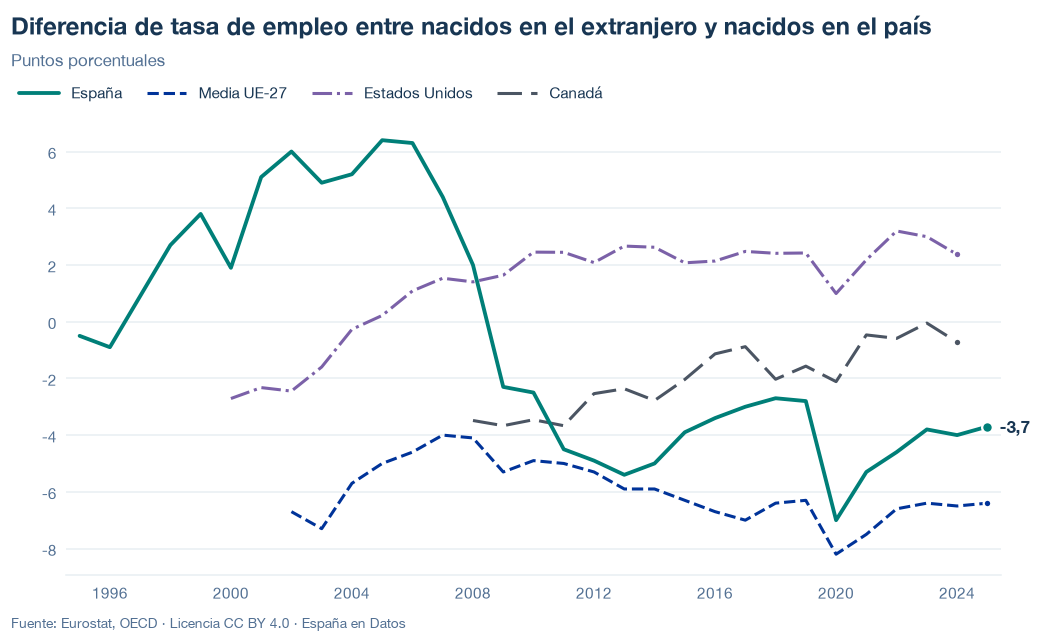

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/brecha-empleo-nacidos-extranjero.json y data/brecha-empleo-nacidos-extranjero.csv


## 6. Fuentes, notas y licencia

- Eurostat, `lfsa_ergacob` (`Y20-64`, `T`, `PC`, `c_birth=FOR` y `NAT`).
- OCDE, resultados laborales de los inmigrantes: `OECD.ELS.IMD,DSD_MIG@DF_MIG_NUP_SEX,1.0` (`EMP_WAP`, `_T`, `FB` y `NB`, `PT_WAP_SUB`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.